In [1]:
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle, Rectangle
from scipy.optimize import curve_fit

In [2]:
fn_les_wake = r"..\data\test_les_data\Flowpos_10D.nc"
fn_les_free = r"..\data\test_les_data\Flowpos_n2D.nc"

### Open LES data

In [3]:
ds_les_wake = xr.open_dataset(fn_les_wake)
ds_les_free = xr.open_dataset(fn_les_free)

### Cut the data to the same extent and interpolate free flow grid to match downstream grid

In [4]:
# Align the y and z ranges of the wake and free-stream datasets
y_min = max(ds_les_wake.y.min().item(), ds_les_free.y.min().item())
y_max = min(ds_les_wake.y.max().item(), ds_les_free.y.max().item())
z_min = max(ds_les_wake.z.min().item(), ds_les_free.z.min().item())
z_max = min(ds_les_wake.z.max().item(), ds_les_free.z.max().item())

ds_les_wake = ds_les_wake.sel(y=slice(y_min, y_max), z=slice(z_min, z_max))
ds_les_free = ds_les_free.sel(y=slice(y_min, y_max), z=slice(z_min, z_max))

# The y spacing differs slightly between the files, so interpolate the free-stream data onto the wake grid
ds_les_free = ds_les_free.interp(y=ds_les_wake.y, z=ds_les_wake.z)

### Mean wind speed field (streamwise)

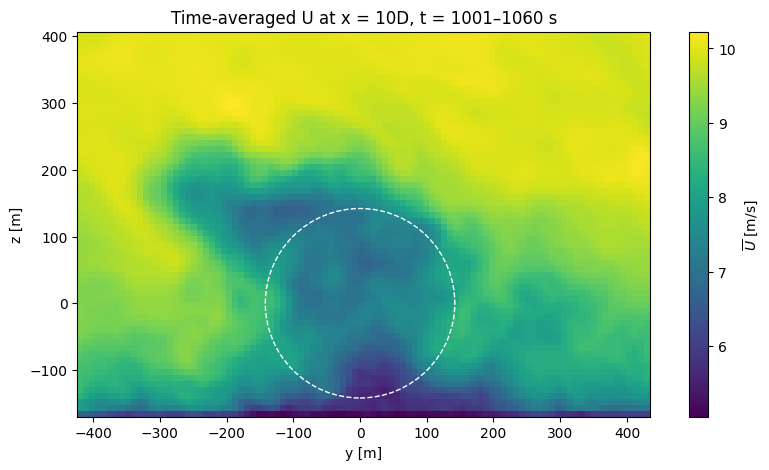

In [5]:
U_mean_wake = ds_les_wake["U"].mean(dim="t").squeeze("x")

R = ds_les_wake["R"].item()
fig, ax = plt.subplots(figsize=(10, 5))
U_mean_wake.plot.pcolormesh(x="y", y="z", ax=ax, cmap="viridis",
                       cbar_kwargs={"label": r"$\overline{U}$ [m/s]"})

# Rotor disk outline (assumes y, z are relative to the rotor centre)
ax.add_patch(Circle((0, 0), R, fill=False, edgecolor="white",
                    linestyle="--", linewidth=1))

ax.set_aspect("equal")
ax.set_xlabel("y [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Time-averaged U at x = {(ds_les_wake.x.item()/(2*R)):.0f}D, "
             f"t = {ds_les_wake.t[0].item():.0f}–{ds_les_wake.t[-1].item():.0f} s")
plt.show()

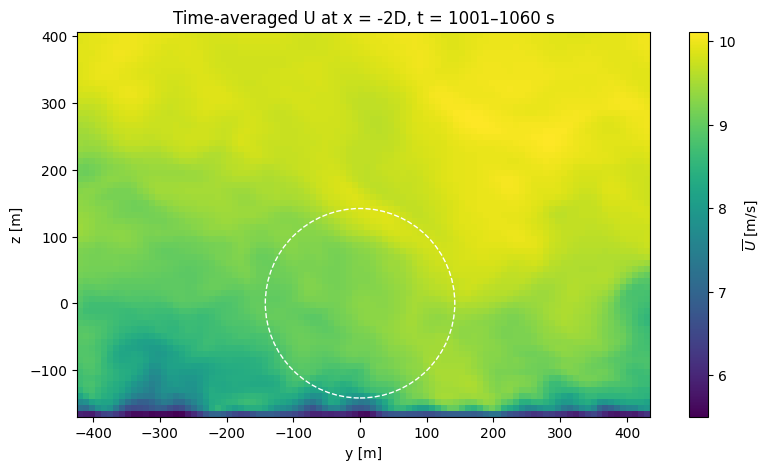

In [6]:
U_mean_free = ds_les_free["U"].mean(dim="t").squeeze("x")

R = ds_les_free["R"].item()
fig, ax = plt.subplots(figsize=(10, 5))
U_mean_free.plot.pcolormesh(x="y", y="z", ax=ax, cmap="viridis",
                       cbar_kwargs={"label": r"$\overline{U}$ [m/s]"})

# Rotor disk outline (assumes y, z are relative to the rotor centre)
ax.add_patch(Circle((0, 0), R, fill=False, edgecolor="white",
                    linestyle="--", linewidth=1))

ax.set_aspect("equal")
ax.set_xlabel("y [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Time-averaged U at x = {(ds_les_free.x.item()/(2*R)):.0f}D, "
             f"t = {ds_les_free.t[0].item():.0f}–{ds_les_free.t[-1].item():.0f} s")
plt.show()

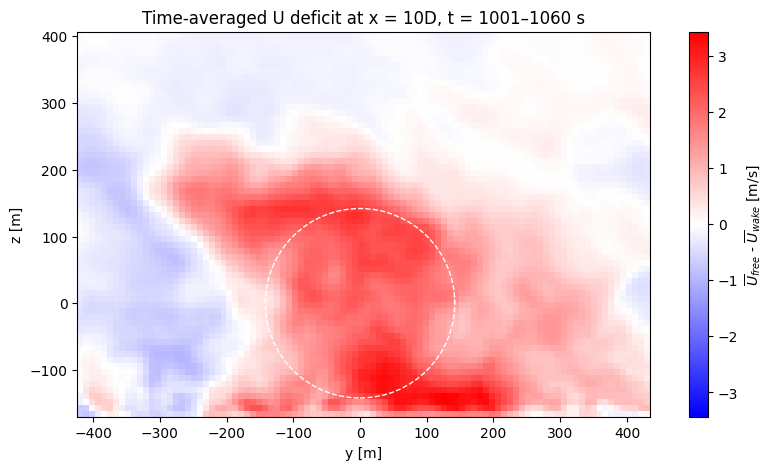

In [7]:
U_mean_diff = U_mean_free - U_mean_wake

R = ds_les_wake["R"].item()
fig, ax = plt.subplots(figsize=(10, 5))
U_mean_diff.plot.pcolormesh(x="y", y="z", ax=ax, cmap="bwr",
                       cbar_kwargs={"label": r"$\overline{U}_{free}$ - $\overline{U}_{wake}$ [m/s]"})

# Rotor disk outline (assumes y, z are relative to the rotor centre)
ax.add_patch(Circle((0, 0), R, fill=False, edgecolor="white",
                    linestyle="--", linewidth=1))

ax.set_aspect("equal")
ax.set_xlabel("y [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Time-averaged U deficit at x = {(ds_les_wake.x.item()/(2*R)):.0f}D, "
             f"t = {ds_les_wake.t[0].item():.0f}–{ds_les_wake.t[-1].item():.0f} s")
plt.show()

### Sample U deficit at rotor centerline and fit Gaussian profile

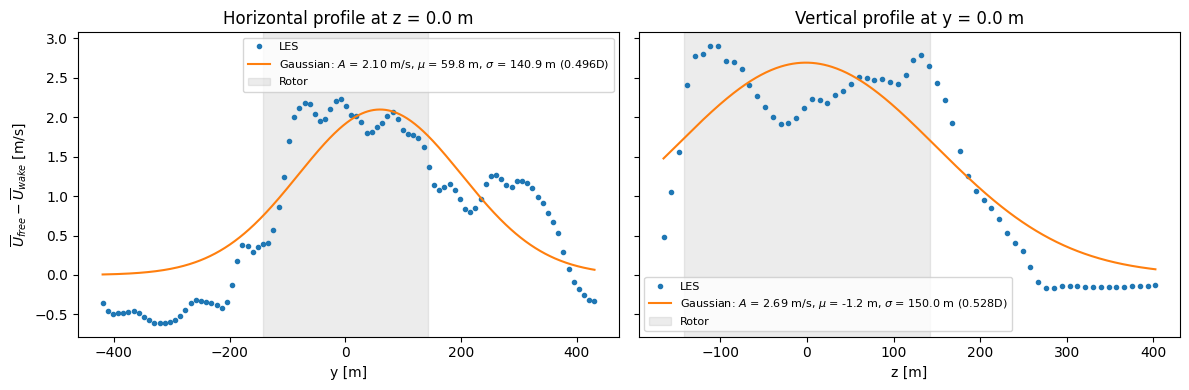

y: A = 2.097 m/s, mu = 59.84 m, sigma = 140.90 m = 0.496D
z: A = 2.691 m/s, mu = -1.21 m, sigma = 150.04 m = 0.528D


In [8]:
def gaussian(s, A, mu, sigma):
    return A * np.exp(-0.5 * ((s - mu) / sigma) ** 2) # Force mu to be 0? wake center at rotor center

# Centerline profiles through the rotor centre, linearly interpolated to exactly z = 0 and y = 0
U_diff_y = U_mean_diff.interp(z=0)
U_diff_z = U_mean_diff.interp(y=0)

fits = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (dim, profile) in zip(axes, [("y", U_diff_y), ("z", U_diff_z)]):
    s = profile[dim].values
    popt, pcov = curve_fit(gaussian, s, profile.values, p0=[profile.max().item(), 0, R])
    fits[dim] = popt
    A, mu, sigma = popt

    s_fine = np.linspace(s.min(), s.max(), 500)
    ax.plot(s, profile.values, "o", markersize=3, label="LES")
    ax.plot(s_fine, gaussian(s_fine, *popt), "-",
            label=rf"Gaussian: $A$ = {A:.2f} m/s, $\mu$ = {mu:.1f} m, $\sigma$ = {sigma:.1f} m ({sigma/(2*R):.3f}D)")
    ax.axvspan(-R, R, color="grey", alpha=0.15, label="Rotor")
    ax.set_xlabel(f"{dim} [m]")
    ax.legend(fontsize=8)

axes[0].set_ylabel(r"$\overline{U}_{free} - \overline{U}_{wake}$ [m/s]")
axes[0].set_title(f"Horizontal profile at z = {U_diff_y.z.item():.1f} m")
axes[1].set_title(f"Vertical profile at y = {U_diff_z.y.item():.1f} m")
plt.tight_layout()
plt.show()

for dim, (A, mu, sigma) in fits.items():
    print(f"{dim}: A = {A:.3f} m/s, mu = {mu:.2f} m, sigma = {sigma:.2f} m = {sigma/(2*R):.3f}D")